# Logistic cuisine classifiers

Compare the lesson’s one-versus-rest liblinear model with multinomial lbfgs on identical untouched test rows. This compares both a solver and a multiclass objective, so any performance difference cannot be attributed to optimization alone. We choose lbfgs as the demonstration model in advance. No test-set parameter selection is performed.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

raw = pd.read_csv(Path("../../../4-Classification/data/cuisines.csv"))
X = raw.drop(columns=["cuisine", "Unnamed: 0", "rice", "garlic", "ginger"]).astype(float)
y = raw.cuisine
# Group identical feature vectors, even when their labels disagree.
groups = pd.util.hash_pandas_object(X, index=False)
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
assert set(groups.iloc[train_idx]).isdisjoint(set(groups.iloc[test_idx]))
assert X.shape[1] == 380 and X.isin([0, 1]).all().all()
print(f"Rows: {len(X)}; train: {len(X_train)}; test: {len(X_test)}; features: {X.shape[1]}")


Rows: 2448; train: 1960; test: 488; features: 380


In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
models = {
    "liblinear OvR": OneVsRestClassifier(LogisticRegression(solver="liblinear", class_weight="balanced", max_iter=2000, random_state=42)),
    "lbfgs multinomial": LogisticRegression(solver="lbfgs", class_weight="balanced", max_iter=2000),
}
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    results.append({"Model": name, "Accuracy": accuracy_score(y_test, prediction), "Macro F1": f1_score(y_test, prediction, average="macro")})
    print(name)
    print(classification_report(y_test, prediction, zero_division=0))
display(pd.DataFrame(results).set_index("Model").round(4))
model = models["lbfgs multinomial"]
assert np.isfinite(pd.DataFrame(results).select_dtypes("number")).all().all()

liblinear OvR
              precision    recall  f1-score   support

     chinese       0.75      0.74      0.74        88
      indian       0.96      0.96      0.96       124
    japanese       0.67      0.66      0.66        61
      korean       0.86      0.86      0.86       152
        thai       0.82      0.84      0.83        63

    accuracy                           0.83       488
   macro avg       0.81      0.81      0.81       488
weighted avg       0.83      0.83      0.83       488

lbfgs multinomial
              precision    recall  f1-score   support

     chinese       0.73      0.69      0.71        88
      indian       0.94      0.95      0.95       124
    japanese       0.65      0.69      0.67        61
      korean       0.89      0.83      0.86       152
        thai       0.77      0.89      0.82        63

    accuracy                           0.83       488
   macro avg       0.80      0.81      0.80       488
weighted avg       0.83      0.83      0.83  

,Accuracy,Macro F1
Model,,
liblinear OvR,0.8340,0.8094
lbfgs multinomial,0.8258,0.8015


,Actual,Predicted,chinese,indian,japanese,korean,thai
0,indian,indian,0.000,1.000,0.000,0.000,0.000
1,indian,indian,0.000,0.973,0.012,0.000,0.015
2,indian,indian,0.008,0.944,0.003,0.001,0.045


Row 0 ingredients: black_pepper, butter, cardamom, cashew, cayenne, chicken, cinnamon, cumin, lemon_juice, raisin, yogurt
Row 10 ingredients: butter, cardamom, cinnamon, coriander, cumin, turmeric, vinegar, wine
Row 30 ingredients: bay, black_pepper, cardamom, cilantro, cinnamon, coriander, tomato


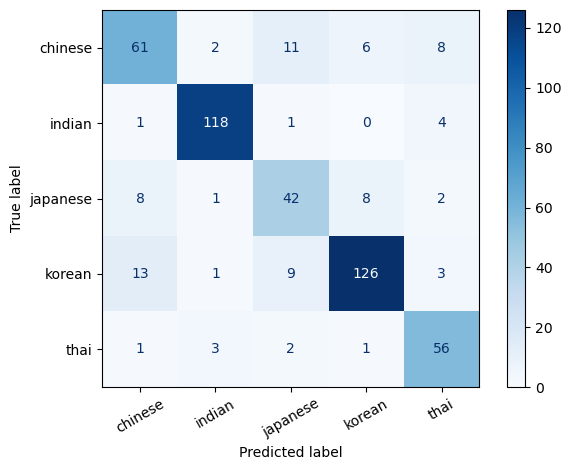

In [3]:
positions = [0, 10, 30]
probabilities = pd.DataFrame(model.predict_proba(X_test.iloc[positions]), columns=model.classes_)
probabilities.insert(0, "Actual", y_test.iloc[positions].to_numpy())
probabilities.insert(1, "Predicted", model.predict(X_test.iloc[positions]))
display(probabilities.round(3))
assert np.allclose(probabilities[model.classes_].sum(axis=1), 1)
for position in positions:
    present = X_test.iloc[position]
    print(f"Row {position} ingredients:", ", ".join(present.index[present == 1]))
ConfusionMatrixDisplay.from_predictions(y_test, model.predict(X_test), labels=model.classes_, cmap="Blues", xticks_rotation=30)
plt.tight_layout()
plt.show()

In [4]:
indian_row = list(model.classes_).index("indian")
contributions = pd.Series(model.coef_[indian_row], index=X.columns).sort_values()
display(contributions.tail(10).rename("Indian class coefficient"))
print("Confidence is a model estimate, not evidence of cultural authenticity or calibrated certainty.")

cashew         1.046401
cilantro       1.060767
lemon_juice    1.124516
turmeric       1.125635
tamarind       1.163127
lime           1.220386
tea            1.235735
cardamom       1.774180
yogurt         1.784153
cumin          2.072589
Name: Indian class coefficient, dtype: float64

Confidence is a model estimate, not evidence of cultural authenticity or calibrated certainty.


## Interpretation

The prediction is the class with the largest probability, and the columns follow `model.classes_`; hard-coding their order is unsafe. The ingredient coefficients show associations learned from these recipes, not causes or universal culinary rules. Large class weights help minority labels influence fitting but may change probability calibration. Correlated ingredients and omitted quantities limit interpretation.

Liblinear solves binary regularized logistic problems; an explicit `OneVsRestClassifier` supplies multiclass behavior without the deprecated `multi_class` argument. L-BFGS uses a limited-memory quasi-Newton method and optimizes the joint multinomial loss here. The two-paragraph assignment and sources are in solver-comparison.docx and answers.md.